# Question 5: RAG Answer Evaluation and Hallucination Detection

In [1]:
# Create 20 knowledge documents

from pathlib import Path

DOCS_DIR = Path("rag_evaluation_docs")
DOCS_DIR.mkdir(exist_ok=True)

knowledge_docs = {
    "01_machine_learning.txt": """
Machine learning enables systems to learn patterns from data.
Its common types are supervised learning, unsupervised learning,
and reinforcement learning. Applications include prediction,
classification, recommendation, and anomaly detection.
""",
    "02_supervised_learning.txt": """
Supervised learning trains a model on labeled examples.
Classification predicts categories, while regression predicts
continuous numerical values. Examples include spam classification
and house-price prediction.
""",
    "03_unsupervised_learning.txt": """
Unsupervised learning finds patterns in unlabeled data.
Clustering groups similar observations. Dimensionality reduction
represents data with fewer features while retaining useful structure.
""",
    "04_reinforcement_learning.txt": """
Reinforcement learning trains an agent through interactions
with an environment. The agent receives rewards or penalties
and learns actions that maximize cumulative reward.
""",
    "05_neural_networks.txt": """
Neural networks contain interconnected computational units
organized into layers. Training adjusts weights to reduce a
loss function. Backpropagation calculates gradients used by
gradient-based optimization.
""",
    "06_deep_learning.txt": """
Deep learning uses neural networks with multiple layers.
It is widely used in image recognition, speech processing,
natural language processing, and complex pattern recognition.
""",
    "07_transformers.txt": """
Transformers use attention mechanisms to model relationships
between tokens. Self-attention allows a token representation
to incorporate information from other tokens in the input.
""",
    "08_nlp.txt": """
Natural language processing enables computers to process
human language. Tasks include text classification, translation,
summarization, information extraction, and question answering.
""",
    "09_embeddings.txt": """
Embeddings represent items such as words or passages as
numerical vectors. Similarity between vectors can help retrieve
semantically related text, but similarity does not guarantee
that a passage answers a question correctly.
""",
    "10_rag.txt": """
Retrieval-augmented generation combines information retrieval
with language generation. A typical pipeline retrieves relevant
passages, supplies them as context to a language model, and
generates an answer grounded in that context.
""",
    "11_vector_databases.txt": """
Vector databases store vectors and associated metadata.
They support similarity search and may support metadata filters.
They are used to retrieve semantically related documents.
""",
    "12_chunking.txt": """
Chunking divides long documents into smaller passages.
Chunk size affects context and retrieval granularity. Overlap
can preserve information across boundaries, but excessive overlap
can create redundant passages and increase storage.
""",
    "13_classification_metrics.txt": """
Accuracy is the fraction of predictions that are correct.
Precision measures the fraction of predicted positives that
are true positives. Recall measures the fraction of actual
positives that are identified. F1 combines precision and recall.
""",
    "14_regression_metrics.txt": """
Mean absolute error averages absolute prediction errors.
Root mean squared error gives greater influence to large errors.
Metric selection depends on the task and the consequences of errors.
""",
    "15_overfitting.txt": """
Overfitting occurs when a model fits training data too closely
and generalizes poorly. Possible remedies include regularization,
data augmentation, early stopping, and suitable validation.
""",
    "16_data_leakage.txt": """
Data leakage occurs when training uses information unavailable
at prediction time or information from evaluation data.
It can produce misleadingly high evaluation scores.
""",
    "17_preprocessing.txt": """
Data preprocessing may include cleaning, missing-value handling,
encoding categorical variables, and feature scaling. Fit learned
preprocessing steps on training data and apply them consistently.
""",
    "18_train_test_split.txt": """
A train-test split separates data used for model fitting from
data used for final evaluation. The test set should not guide
repeated model tuning. Validation data can support model selection.
""",
    "19_faithfulness.txt": """
Faithfulness in retrieval-augmented generation concerns whether
an answer's claims are supported by the retrieved context.
A fluent answer can still contain unsupported or fabricated claims.
""",
    "20_evaluation.txt": """
RAG evaluation can measure retrieval relevance, answer correctness,
completeness, and faithfulness. Reference answers help assess
correctness and completeness. Human review is useful because
automatic evaluation metrics can make mistakes.
"""
}

for filename, content in knowledge_docs.items():
    (DOCS_DIR / filename).write_text(content.strip(), encoding="utf-8")

print("Documents created:", len(knowledge_docs))
print("Folder:", DOCS_DIR.resolve())


Documents created: 20
Folder: C:\Users\HP\rag_evaluation_docs


In [2]:
# Create 15 test questions with reference answers

import pandas as pd

test_data = [
    ("What is machine learning?",
     "Machine learning enables systems to learn patterns from data."),
    ("What is supervised learning?",
     "It trains models using labeled examples."),
    ("What is the difference between classification and regression?",
     "Classification predicts categories, while regression predicts numerical values."),
    ("What does unsupervised learning do?",
     "It discovers patterns in unlabeled data."),
    ("How does reinforcement learning work?",
     "An agent interacts with an environment and learns from rewards or penalties."),
    ("What is backpropagation used for?",
     "It calculates gradients used to adjust neural network weights during training."),
    ("What is self-attention?",
     "It allows a token representation to incorporate information from other tokens."),
    ("What are embeddings?",
     "Embeddings represent items such as text as numerical vectors."),
    ("What is RAG?",
     "RAG retrieves relevant passages and uses them as context for language generation."),
    ("What is a vector database used for?",
     "It stores vectors and supports similarity search, often with metadata."),
    ("Why is chunk overlap used?",
     "Overlap helps preserve information across chunk boundaries."),
    ("What is the difference between precision and recall?",
     "Precision measures correctness among predicted positives; recall measures identified actual positives."),
    ("What is overfitting?",
     "Overfitting occurs when a model fits training data closely but generalizes poorly."),
    ("What is data leakage?",
     "It occurs when training uses information unavailable at prediction time or from evaluation data."),
    ("What is faithfulness in RAG?",
     "Faithfulness measures whether answer claims are supported by retrieved context.")
]

test_df = pd.DataFrame(
    test_data,
    columns=["Question", "Reference_Answer"]
)

print("Test questions:", len(test_df))
display(test_df.head())


Test questions: 15


,Question,Reference_Answer
0,What is machine learning?,Machine learning enables systems to learn patt...
1,What is supervised learning?,It trains models using labeled examples.
2,What is the difference between classification ...,"Classification predicts categories, while regr..."
3,What does unsupervised learning do?,It discovers patterns in unlabeled data.
4,How does reinforcement learning work?,An agent interacts with an environment and lea...


In [3]:
# Build the ChromaDB knowledge base

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import OllamaEmbeddings, ChatOllama
from langchain_chroma import Chroma

documents = [
    Document(
        page_content=path.read_text(encoding="utf-8"),
        metadata={"source": path.name}
    )
    for path in sorted(DOCS_DIR.glob("*.txt"))
]

splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,
    chunk_overlap=60
)

chunks = splitter.split_documents(documents)

embeddings = OllamaEmbeddings(model="nomic-embed-text")

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    collection_name="rag_evaluation",
    persist_directory="rag_evaluation_db"
)

llm = ChatOllama(model="llama3.2", temperature=0)

print("Documents:", len(documents))
print("Chunks:", len(chunks))
print("ChromaDB ready.")


Documents: 20
Chunks: 20
ChromaDB ready.


In [4]:
# Run RAG and baseline answers

import time

results = []

for i, row in test_df.iterrows():
    question = row["Question"]
    reference = row["Reference_Answer"]

    # RAG: retrieve supporting passages
    start = time.perf_counter()
    retrieved_docs = vectorstore.similarity_search(question, k=3)
    retrieval_time = time.perf_counter() - start

    context = "\n\n".join(
        f"[S{j}] {doc.metadata['source']}\n{doc.page_content}"
        for j, doc in enumerate(retrieved_docs, start=1)
    )

    rag_prompt = f"""
Answer using only the supplied evidence.
If the evidence is insufficient, say so.
Do not invent facts.

Question: {question}
Evidence:
{context}

Answer:
"""

    start = time.perf_counter()
    rag_answer = llm.invoke(rag_prompt).content
    rag_generation_time = time.perf_counter() - start

    # Baseline: same LLM without retrieved context
    baseline_prompt = f"""
Answer the following question from your general knowledge.
Do not claim that you consulted documents.

Question: {question}
Answer:
"""

    start = time.perf_counter()
    baseline_answer = llm.invoke(baseline_prompt).content
    baseline_generation_time = time.perf_counter() - start

    results.append({
        "Question": question,
        "Reference_Answer": reference,
        "Retrieved_Passages": context,
        "Retrieved_Sources": "; ".join(
            doc.metadata["source"] for doc in retrieved_docs
        ),
        "RAG_Answer": rag_answer,
        "Baseline_Answer": baseline_answer,
        "Retrieval_Time_Seconds": retrieval_time,
        "RAG_Generation_Time_Seconds": rag_generation_time,
        "Baseline_Generation_Time_Seconds": baseline_generation_time
    })

    print(f"Completed {i + 1}/15")

results_df = pd.DataFrame(results)
display(results_df[[
    "Question", "RAG_Answer", "Baseline_Answer"
]].head())


Completed 1/15
Completed 2/15
Completed 3/15
Completed 4/15
Completed 5/15
Completed 6/15
Completed 7/15
Completed 8/15
Completed 9/15
Completed 10/15
Completed 11/15
Completed 12/15
Completed 13/15
Completed 14/15
Completed 15/15


,Question,RAG_Answer,Baseline_Answer
0,What is machine learning?,"Based on the provided evidence, machine learni...",Machine learning is a type of artificial intel...
1,What is supervised learning?,Supervised learning trains a model on labeled ...,Supervised learning is a type of machine learn...
2,What is the difference between classification ...,"Based on the provided evidence, the difference...",Classification and regression are two fundamen...
3,What does unsupervised learning do?,"Based on the provided evidence, unsupervised l...",Unsupervised learning is a type of machine lea...
4,How does reinforcement learning work?,"Based on the provided evidence, here's what ca...",Reinforcement learning (RL) is a type of machi...


In [6]:
# Evaluate the generated answers

import json
import re

def judge_answer(question, reference, answer, evidence):
    prompt = f"""
Evaluate an answer against the reference and evidence.
Return JSON only with integer scores from 1 to 5:
{{
 "correctness": 1,
 "completeness": 1,
 "faithfulness": 1
}}

Correctness: agreement with the reference answer.
Completeness: coverage of important reference points.
Faithfulness: support for factual claims in the evidence.
Give a low faithfulness score for unsupported claims.
If evidence is empty, faithfulness must not be assumed.

Question: {question}
Reference: {reference}
Answer: {answer}
Evidence: {evidence}
"""

    response = llm.invoke(prompt).content
    match = re.search(r"\{.*\}", response, re.S)

    if not match:
        return {
            "correctness": None,
            "completeness": None,
            "faithfulness": None
        }

    try:
        data = json.loads(match.group())
        output = {}
        for metric in ["correctness", "completeness", "faithfulness"]:
            score = int(data[metric])
            output[metric] = score if 1 <= score <= 5 else None
        return output
    except (ValueError, KeyError, json.JSONDecodeError):
        return {
            "correctness": None,
            "completeness": None,
            "faithfulness": None
        }

for i, row in results_df.iterrows():
    # Score retrieval relevance using the proportion of retrieved passages
    # judged relevant by the LLM.
    relevance_prompt = f"""
Score the relevance of the retrieved passages to the question
from 1 to 5. Score based on useful information present, not writing quality.
Return only one integer.

Question: {row['Question']}
Retrieved passages: {row['Retrieved_Passages']}
"""

    relevance_response = llm.invoke(relevance_prompt).content.strip()
    match = re.search(r"\b([1-5])\b", relevance_response)
    relevance = int(match.group(1)) if match else None

    rag_scores = judge_answer(
        row["Question"], row["Reference_Answer"],
        row["RAG_Answer"], row["Retrieved_Passages"]
    )

    baseline_scores = judge_answer(
        row["Question"], row["Reference_Answer"],
        row["Baseline_Answer"], ""
    )

    for metric, value in rag_scores.items():
        results_df.loc[i, "RAG_" + metric.capitalize()] = value

    for metric, value in baseline_scores.items():
        results_df.loc[i, "Baseline_" + metric.capitalize()] = value

    results_df.loc[i, "Retrieval_Relevance"] = relevance
    print(f"Evaluated {i + 1}/15")


Evaluated 1/15
Evaluated 2/15
Evaluated 3/15
Evaluated 4/15
Evaluated 5/15
Evaluated 6/15
Evaluated 7/15
Evaluated 8/15
Evaluated 9/15
Evaluated 10/15
Evaluated 11/15
Evaluated 12/15
Evaluated 13/15
Evaluated 14/15
Evaluated 15/15


In [7]:
# Create the comparison table and graphs

import matplotlib.pyplot as plt

score_columns = [
    "Retrieval_Relevance",
    "RAG_Correctness",
    "RAG_Completeness",
    "RAG_Faithfulness",
    "Baseline_Correctness",
    "Baseline_Completeness"
]

for column in score_columns:
    results_df[column] = pd.to_numeric(
        results_df[column], errors="coerce"
    )

summary = results_df[score_columns].mean().to_frame(
    name="Mean_Score"
)

display(summary.round(2))

results_df.to_csv("rag_evaluation_results.csv", index=False)
summary.to_csv("rag_evaluation_summary.csv")


,Mean_Score
Retrieval_Relevance,3.20
RAG_Correctness,4.13
RAG_Completeness,4.00
RAG_Faithfulness,3.47
Baseline_Correctness,4.47
Baseline_Completeness,5.00


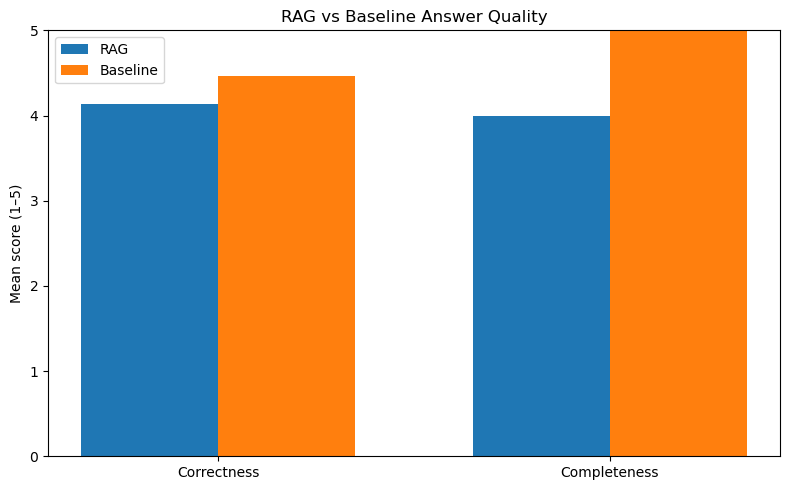

In [8]:
# Create the correctness and completeness graph

metrics = ["Correctness", "Completeness"]

rag_means = [
    results_df["RAG_Correctness"].mean(),
    results_df["RAG_Completeness"].mean()
]

baseline_means = [
    results_df["Baseline_Correctness"].mean(),
    results_df["Baseline_Completeness"].mean()
]

x = range(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar([i - width/2 for i in x], rag_means,
        width=width, label="RAG")
plt.bar([i + width/2 for i in x], baseline_means,
        width=width, label="Baseline")

plt.xticks(list(x), metrics)
plt.ylabel("Mean score (1–5)")
plt.title("RAG vs Baseline Answer Quality")
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()
plt.savefig("rag_vs_baseline_quality.png", dpi=150)
plt.show()


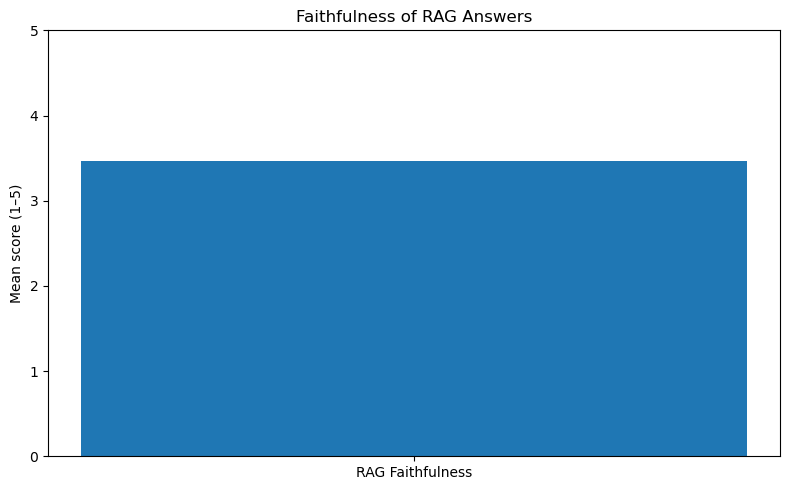

In [9]:
# Create a faithfulness graph

plt.figure(figsize=(8, 5))

plt.bar(
    ["RAG Faithfulness"],
    [results_df["RAG_Faithfulness"].mean()]
)

plt.ylabel("Mean score (1–5)")
plt.title("Faithfulness of RAG Answers")
plt.ylim(0, 5)
plt.tight_layout()
plt.savefig("rag_faithfulness.png", dpi=150)
plt.show()


In [10]:
# Identify at least three failure cases

failure_cases = results_df[
    (results_df["RAG_Correctness"] <= 2) |
    (results_df["RAG_Faithfulness"] <= 2) |
    (results_df["RAG_Completeness"] <= 2)
]

display(failure_cases[[
    "Question",
    "Reference_Answer",
    "Retrieved_Passages",
    "RAG_Answer",
    "RAG_Correctness",
    "RAG_Completeness",
    "RAG_Faithfulness"
]])

print("Potential failure cases:", len(failure_cases))


,Question,Reference_Answer,Retrieved_Passages,RAG_Answer,RAG_Correctness,RAG_Completeness,RAG_Faithfulness
6,What is self-attention?,It allows a token representation to incorporat...,[S1] 07_transformers.txt\nTransformers use att...,The evidence does not provide a clear definiti...,4.0,4.0,2.0
7,What are embeddings?,Embeddings represent items such as text as num...,[S1] 09_embeddings.txt\nEmbeddings represent i...,The evidence does not provide a clear definiti...,4.0,4.0,2.0
10,Why is chunk overlap used?,Overlap helps preserve information across chun...,[S1] 12_chunking.txt\nChunking divides long do...,The evidence does not provide a clear answer o...,3.0,4.0,2.0
11,What is the difference between precision and r...,Precision measures correctness among predicted...,[S1] 13_classification_metrics.txt\nAccuracy i...,The evidence does not provide a clear definiti...,4.0,3.0,2.0
12,What is overfitting?,Overfitting occurs when a model fits training ...,[S1] 15_overfitting.txt\nOverfitting occurs wh...,"Based on the provided evidence, overfitting is...",4.0,3.0,2.0
13,What is data leakage?,It occurs when training uses information unava...,[S1] 16_data_leakage.txt\nData leakage occurs ...,"Based on the provided evidence, I can only mak...",4.0,3.0,2.0


Potential failure cases: 6


In [11]:
# nspect the actual failure cases
for i, row in failure_cases.iterrows():
    print("\n" + "=" * 70)
    print("QUESTION:", row["Question"])
    print("\nREFERENCE:", row["Reference_Answer"])
    print("\nRETRIEVED EVIDENCE:", row["Retrieved_Passages"])
    print("\nRAG ANSWER:", row["RAG_Answer"])
    print(
        "\nScores:",
        "Correctness =", row["RAG_Correctness"],
        "| Completeness =", row["RAG_Completeness"],
        "| Faithfulness =", row["RAG_Faithfulness"]
    )


QUESTION: What is self-attention?

REFERENCE: It allows a token representation to incorporate information from other tokens.

RETRIEVED EVIDENCE: [S1] 07_transformers.txt
Transformers use attention mechanisms to model relationships
between tokens. Self-attention allows a token representation
to incorporate information from other tokens in the input.

[S2] 20_evaluation.txt
RAG evaluation can measure retrieval relevance, answer correctness,
completeness, and faithfulness. Reference answers help assess
correctness and completeness. Human review is useful because
automatic evaluation metrics can make mistakes.

[S3] 01_machine_learning.txt
Machine learning enables systems to learn patterns from data.
Its common types are supervised learning, unsupervised learning,
and reinforcement learning. Applications include prediction,
classification, recommendation, and anomaly detection.

RAG ANSWER: The evidence does not provide a clear definition of self-attention. However, it does mention that 

In [13]:
# Improve the answer-generation prompt
rag_prompt = f"""
You are a question-answering system evaluated on document evidence.

Answer the question directly using the retrieved passages.
Read all passages carefully before deciding that information is missing.
If a passage contains the answer, explain it clearly in your own words.
Cite the supporting source label, such as [S1].
Do not invent facts or add unsupported details.
Only state that evidence is insufficient if the passages truly do
not contain enough information to answer the question.

Question:
{question}

Retrieved evidence:
{context}

Answer:
"""

In [14]:
test_question = "What is self-attention?"

test_docs = vectorstore.similarity_search(
    test_question,
    k=3
)

test_context = "\n\n".join(
    f"[S{i}] {doc.metadata['source']}\n{doc.page_content}"
    for i, doc in enumerate(test_docs, 1)
)

test_response = llm.invoke(
    rag_prompt.replace(question, test_question).replace(
        context, test_context
    )
)

print(test_response.content)

Self-attention is a mechanism used in transformers to model relationships between tokens in the input. It allows a token representation to incorporate information from other tokens, enabling the model to better understand the context and relationships within the input data.

This is explained in [S1], which states that self-attention "allows a token representation to incorporate information from other tokens in the input."


In [15]:
results_df.to_csv(
    "rag_evaluation_results_improved.csv",
    index=False
)

print("Improved evaluation results saved.")

Improved evaluation results saved.


In [16]:
print("Total questions:", len(results_df))

display(
    results_df[
        ["Question", "RAG_Answer"]
    ].head(5)
)

Total questions: 15


,Question,RAG_Answer
0,What is machine learning?,"Based on the provided evidence, machine learni..."
1,What is supervised learning?,Supervised learning trains a model on labeled ...
2,What is the difference between classification ...,"Based on the provided evidence, the difference..."
3,What does unsupervised learning do?,"Based on the provided evidence, unsupervised l..."
4,How does reinforcement learning work?,"Based on the provided evidence, here's what ca..."


In [17]:
results_df.to_csv(
    "rag_evaluation_results_improved.csv",
    index=False
)

print("Updated results saved:", len(results_df))

Updated results saved: 15


In [18]:
# Check the evaluation columns
print("Evaluation columns:")
print(results_df.columns.tolist())

display(results_df.head(5))

Evaluation columns:
['Question', 'Reference_Answer', 'Retrieved_Passages', 'Retrieved_Sources', 'RAG_Answer', 'Baseline_Answer', 'Retrieval_Time_Seconds', 'RAG_Generation_Time_Seconds', 'Baseline_Generation_Time_Seconds', 'RAG_Correctness', 'RAG_Completeness', 'RAG_Faithfulness', 'Baseline_Correctness', 'Baseline_Completeness', 'Baseline_Faithfulness', 'Retrieval_Relevance']


,Question,Reference_Answer,Retrieved_Passages,Retrieved_Sources,RAG_Answer,Baseline_Answer,Retrieval_Time_Seconds,RAG_Generation_Time_Seconds,Baseline_Generation_Time_Seconds,RAG_Correctness,RAG_Completeness,RAG_Faithfulness,Baseline_Correctness,Baseline_Completeness,Baseline_Faithfulness,Retrieval_Relevance
0,What is machine learning?,Machine learning enables systems to learn patt...,[S1] 01_machine_learning.txt\nMachine learning...,01_machine_learning.txt; 06_deep_learning.txt;...,"Based on the provided evidence, machine learni...",Machine learning is a type of artificial intel...,0.054120,7.771315,11.209580,5.0,4.0,4.0,4.0,5.0,5.0,4.0
1,What is supervised learning?,It trains models using labeled examples.,[S1] 01_machine_learning.txt\nMachine learning...,01_machine_learning.txt; 02_supervised_learnin...,Supervised learning trains a model on labeled ...,Supervised learning is a type of machine learn...,0.027792,3.515069,18.127381,5.0,5.0,5.0,5.0,5.0,5.0,3.0
2,What is the difference between classification ...,"Classification predicts categories, while regr...",[S1] 02_supervised_learning.txt\nSupervised le...,02_supervised_learning.txt; 01_machine_learnin...,"Based on the provided evidence, the difference...",Classification and regression are two fundamen...,0.043881,5.588800,20.939403,4.0,5.0,5.0,5.0,5.0,5.0,4.0
3,What does unsupervised learning do?,It discovers patterns in unlabeled data.,[S1] 03_unsupervised_learning.txt\nUnsupervise...,03_unsupervised_learning.txt; 01_machine_learn...,"Based on the provided evidence, unsupervised l...",Unsupervised learning is a type of machine lea...,0.048983,11.639950,23.292887,5.0,5.0,5.0,5.0,5.0,5.0,3.0
4,How does reinforcement learning work?,An agent interacts with an environment and lea...,[S1] 04_reinforcement_learning.txt\nReinforcem...,04_reinforcement_learning.txt; 01_machine_lear...,"Based on the provided evidence, here's what ca...",Reinforcement learning (RL) is a type of machi...,0.037112,7.541492,55.177755,4.0,4.0,5.0,4.0,5.0,5.0,4.0


In [19]:
# Check whether the evaluation is complete
score_columns = [
    "Retrieval_Relevance",
    "RAG_Correctness",
    "RAG_Completeness",
    "RAG_Faithfulness",
    "Baseline_Correctness",
    "Baseline_Completeness"
]

print("Total evaluated questions:", len(results_df))

for col in score_columns:
    if col in results_df.columns:
        print(
            f"{col}:",
            "missing =", results_df[col].isna().sum(),
            "| mean =", round(results_df[col].mean(), 2)
        )
    else:
        print(f"{col}: MISSING COLUMN")

Total evaluated questions: 15
Retrieval_Relevance: missing = 0 | mean = 3.2
RAG_Correctness: missing = 0 | mean = 4.13
RAG_Completeness: missing = 0 | mean = 4.0
RAG_Faithfulness: missing = 0 | mean = 3.47
Baseline_Correctness: missing = 0 | mean = 4.47
Baseline_Completeness: missing = 0 | mean = 5.0


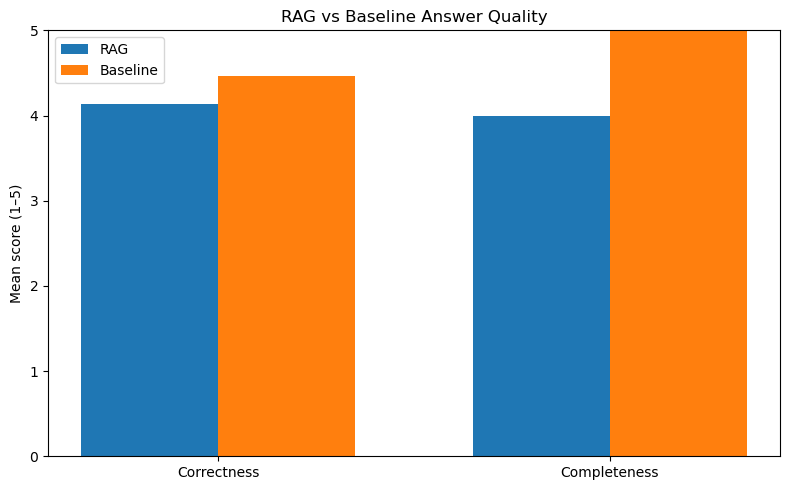

In [20]:
# Generate the final comparison graphs
import matplotlib.pyplot as plt

metrics = ["Correctness", "Completeness"]

rag_scores = [
    results_df["RAG_Correctness"].mean(),
    results_df["RAG_Completeness"].mean()
]

baseline_scores = [
    results_df["Baseline_Correctness"].mean(),
    results_df["Baseline_Completeness"].mean()
]

x = range(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    [i - width/2 for i in x],
    rag_scores,
    width,
    label="RAG"
)

plt.bar(
    [i + width/2 for i in x],
    baseline_scores,
    width,
    label="Baseline"
)

plt.xticks(list(x), metrics)
plt.ylabel("Mean score (1–5)")
plt.title("RAG vs Baseline Answer Quality")
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()
plt.savefig("rag_vs_baseline_quality.png", dpi=150)
plt.show()

In [21]:
results_df.to_csv(
    "rag_evaluation_results_improved.csv",
    index=False
)

print("Final results saved:", len(results_df))

Final results saved: 15
